In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

pd.set_option("display.max_colwidth", 120)
SEED = 42
np.random.seed(SEED)

In [3]:
# Google Colab
PATH = Path("/content/processed")

# Local (comment the Colab line above and uncomment this line)
# PATH = Path("diplomacy-deception-detection/artifacts/processed")

for task in ["actual_lie", "suspected_lie"]:
    for split in ["train", "validation", "test"]:
        file = PATH / task / f"{split}.jsonl"
        print(file, ":", file.exists())

/content/processed/actual_lie/train.jsonl : True
/content/processed/actual_lie/validation.jsonl : True
/content/processed/actual_lie/test.jsonl : True
/content/processed/suspected_lie/train.jsonl : True
/content/processed/suspected_lie/validation.jsonl : True
/content/processed/suspected_lie/test.jsonl : True


In [4]:
def read_jsonl(file):
    with open(file, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

datasets = {}
for task in ["actual_lie", "suspected_lie"]:
    datasets[task] = {}
    for split in ["train", "validation", "test"]:
        datasets[task][split] = pd.DataFrame(
            read_jsonl(PATH / task / f"{split}.jsonl")
        )
        print(task, split, "messages:", len(datasets[task][split]))

display(datasets["actual_lie"]["train"][[
    "message_id", "game_id", "message", "target"
]].head(3))

actual_lie train messages: 13132
actual_lie validation messages: 1416
actual_lie test messages: 2741
suspected_lie train messages: 12025
suspected_lie validation messages: 1283
suspected_lie test messages: 2475


,message_id,game_id,message,target
0,1:0:0,1,Germany!\n\nJust the person I want to speak with. I have a somewhat crazy idea that I’ve always wanted to try with I...,0
1,1:0:1,1,"You've whet my appetite, Italy. What's the suggestion?",0
2,1:0:2,1,👍,0


In [5]:
for task, split_frames in datasets.items():
    print("\nTask:", task)
    games = {}
    for split, frame in split_frames.items():
        assert frame["target"].isin([0, 1]).all(), "Unexpected target"
        assert frame["message_id"].notna().all()
        assert frame["message_id"].is_unique, "Duplicate message IDs"
        games[split] = set(frame["game_id"])
        print(split, "| target counts:", frame["target"].value_counts().to_dict(),
              "| unique games:", len(games[split]))
    assert not (games["train"] & games["validation"])
    assert not (games["train"] & games["test"])
    assert not (games["validation"] & games["test"])

print("\nLabel and game-split checks passed.")


Task: actual_lie
train | target counts: {0: 12541, 1: 591} | unique games: 9
validation | target counts: {0: 1360, 1: 56} | unique games: 1
test | target counts: {0: 2501, 1: 240} | unique games: 2

Task: suspected_lie
train | target counts: {0: 11459, 1: 566} | unique games: 9
validation | target counts: {0: 1236, 1: 47} | unique games: 1
test | target counts: {0: 2310, 1: 165} | unique games: 2

Label and game-split checks passed.


In [6]:
# Bag-of-Words
example_messages = [
    "I trust you",
    "You trust me",
    "I do not trust you"
]

example_vectorizer = CountVectorizer(
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b"
)
X_example = example_vectorizer.fit_transform(example_messages)

example_table = pd.DataFrame(
    X_example.toarray(),
    columns=example_vectorizer.get_feature_names_out(),
    index=example_messages
)
display(example_table)
print("Matrix shape:", X_example.shape)

,do,i,me,not,trust,you
I trust you,0,1,0,0,1,1
You trust me,0,0,1,0,1,1
I do not trust you,1,1,0,1,1,1


Matrix shape: (3, 6)


#### Fit BoW on training messages only


In [7]:
vectorizers = {}
bow = {}
texts = {}

for task, split_frames in datasets.items():
    texts[task] = {
        split: frame["message"].fillna("").astype(str).tolist()
        for split, frame in split_frames.items()
    }

    vectorizer = CountVectorizer(
        lowercase=True,
        token_pattern=r"(?u)\b\w+\b"
    )

    bow[task] = {
        "train": vectorizer.fit_transform(texts[task]["train"])
    }
    for split in ["validation", "test"]:
        bow[task][split] = vectorizer.transform(texts[task][split])

    vectorizers[task] = vectorizer
    print(task, "| vocabulary size:", len(vectorizer.vocabulary_))
    for split in ["train", "validation", "test"]:
        print(" ", split, ":", bow[task][split].shape)

actual_lie | vocabulary size: 7790
  train : (13132, 7790)
  validation : (1416, 7790)
  test : (2741, 7790)
suspected_lie | vocabulary size: 7545
  train : (12025, 7545)
  validation : (1283, 7545)
  test : (2475, 7545)


#### Inspect the learned vocabulary


In [8]:
TASK = "actual_lie"  # Switch to "suspected_lie" to inspect the other task

vocabulary = vectorizers[TASK].vocabulary_
feature_names = vectorizers[TASK].get_feature_names_out()

print("Task:", TASK)
print("Vocabulary size:", len(vocabulary))
print("First 25 words alphabetically:")
print(feature_names[:25].tolist())

vocabulary_examples = pd.DataFrame({
    "word": feature_names[:20],
    "column_index": np.arange(min(20, len(feature_names)))
})
display(vocabulary_examples)

Task: actual_lie
Vocabulary size: 7790
First 25 words alphabetically:
['0', '01', '02', '03', '05', '08', '1', '10', '100', '1000', '100000', '10pm', '11', '110', '11th', '12', '13', '13199396', '13hrs', '14', '15', '16', '17', '18', '1901']


,word,column_index
0,0,0
1,01,1
2,02,2
3,03,3
4,05,4
5,08,5
6,1,6
7,10,7
8,100,8
9,1000,9


#### Check sparse matrix size and density


In [9]:
density_rows = []
for task in ["actual_lie", "suspected_lie"]:
    for split in ["train", "validation", "test"]:
        X = bow[task][split]
        total_cells = X.shape[0] * X.shape[1]
        density_rows.append({
            "task": task,
            "split": split,
            "rows": X.shape[0],
            "features": X.shape[1],
            "nonzero_entries": X.nnz,
            "density_percent": round(100 * X.nnz / total_cells, 4) if total_cells else 0
        })

display(pd.DataFrame(density_rows))

,task,split,rows,features,nonzero_entries,density_percent
0,actual_lie,train,13132,7790,241530,0.2361
1,actual_lie,validation,1416,7790,22977,0.2083
2,actual_lie,test,2741,7790,46695,0.2187
3,suspected_lie,train,12025,7545,222359,0.2451
4,suspected_lie,validation,1283,7545,20847,0.2154
5,suspected_lie,test,2475,7545,41954,0.2247


#### Explore one actual message as a BoW vector


In [10]:
MESSAGE_INDEX = 0
frame = datasets[TASK]["train"]
X = bow[TASK]["train"]
assert 0 <= MESSAGE_INDEX < len(frame)

print("Message ID:", frame.iloc[MESSAGE_INDEX]["message_id"])
print("Target:", frame.iloc[MESSAGE_INDEX]["target"])
print("Message:", frame.iloc[MESSAGE_INDEX]["message"][:700])

row = X.getrow(MESSAGE_INDEX)
word_counts = pd.DataFrame({
    "word": vectorizers[TASK].get_feature_names_out()[row.indices],
    "count": row.data
}).sort_values(["count", "word"], ascending=[False, True])

print("Nonzero features:", row.nnz)
display(word_counts.head(25))

Message ID: 1:0:0
Target: 0
Message: Germany!

Just the person I want to speak with. I have a somewhat crazy idea that I’ve always wanted to try with I/G, but I’ve never actually convinced the other guy to try it. And, what’s worse, it might make you suspicious of me. 

So...do I suggest it?

I’m thinking that this is a low stakes game, not a tournament or anything, and an interesting and unusual move set might make it more fun? That’s my hope anyway.

What is your appetite like for unusual and crazy?
Nonzero features: 65


,word,count
4,i,7
27,and,4
26,it,4
10,a,3
14,that,3
6,to,3
12,crazy,2
43,is,2
32,make,2
31,might,2


#### Find the most frequent training words

Sum word counts across **training messages only**. Frequent words often include common conversational terms, not necessarily useful deception indicators.

,word,count
3406,i,13083
6979,to,11711
7769,you,9430
6876,the,6592
386,and,5540
101,a,4829
6873,that,4722
3486,in,3809
3687,it,3576
4179,me,3046


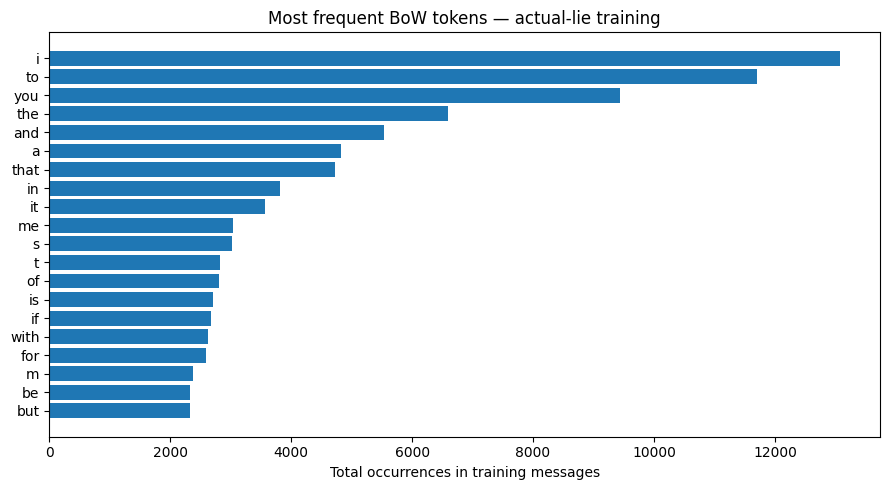

In [11]:
def most_frequent_words(task, top_n=20):
    X = bow[task]["train"]
    counts = np.asarray(X.sum(axis=0)).ravel()
    words = vectorizers[task].get_feature_names_out()
    return pd.DataFrame({
        "word": words,
        "count": counts.astype(int)
    }).sort_values(["count", "word"], ascending=[False, True]).head(top_n)

top_words = most_frequent_words("actual_lie", 20)
display(top_words)

plt.figure(figsize=(9, 5))
plt.barh(top_words["word"][::-1], top_words["count"][::-1])
plt.xlabel("Total occurrences in training messages")
plt.title("Most frequent BoW tokens — actual-lie training")
plt.tight_layout()
plt.show()

#### Compare frequent words between labels


In [12]:
def counts_by_label(task):
    X = bow[task]["train"]
    y = datasets[task]["train"]["target"].to_numpy(dtype=int)
    words = vectorizers[task].get_feature_names_out()
    count_0 = np.asarray(X[y == 0].sum(axis=0)).ravel()
    count_1 = np.asarray(X[y == 1].sum(axis=0)).ravel()
    return pd.DataFrame({
        "word": words,
        "target_0_count": count_0.astype(int),
        "target_1_count": count_1.astype(int)
    })

class_word_counts = counts_by_label("actual_lie")
print("Most frequent words in truthful messages:")
display(class_word_counts.sort_values("target_0_count", ascending=False).head(15))

print("Most frequent words in deceptive messages:")
display(class_word_counts.sort_values("target_1_count", ascending=False).head(15))

Most frequent words in truthful messages:


,word,target_0_count,target_1_count
3406,i,12079,1004
6979,to,10886,825
7769,you,8818,612
6876,the,6206,386
386,and,5082,458
101,a,4542,287
6873,that,4437,285
3486,in,3559,250
3687,it,3348,228
5821,s,2834,188


Most frequent words in deceptive messages:


,word,target_0_count,target_1_count
3406,i,12079,1004
6979,to,10886,825
7769,you,8818,612
386,and,5082,458
6876,the,6206,386
101,a,4542,287
6873,that,4437,285
3486,in,3559,250
4179,me,2806,240
3687,it,3348,228


#### Compare normalized word frequencies


In [13]:
def normalized_word_table(task):
    table = counts_by_label(task).copy()
    total_0 = table["target_0_count"].sum()
    total_1 = table["target_1_count"].sum()

    table["per_1000_target_0"] = (
        1000 * table["target_0_count"] / total_0 if total_0 else 0
    )
    table["per_1000_target_1"] = (
        1000 * table["target_1_count"] / total_1 if total_1 else 0
    )
    table["difference_per_1000"] = (
        table["per_1000_target_1"] - table["per_1000_target_0"]
    )
    return table

frequency_comparison = normalized_word_table("actual_lie")

# Limit to words occurring at least 20 times overall, so rare one-off words
# do not dominate the exploratory ranking.
frequent = frequency_comparison[
    frequency_comparison["target_0_count"]
    + frequency_comparison["target_1_count"] >= 20
].copy()

print("Words relatively more frequent in deceptive messages:")
display(frequent.sort_values("difference_per_1000", ascending=False).head(15))

print("Words relatively more frequent in truthful messages:")
display(frequent.sort_values("difference_per_1000").head(15))

Words relatively more frequent in deceptive messages:


,word,target_0_count,target_1_count,per_1000_target_0,per_1000_target_1,difference_per_1000
3406,i,12079,1004,45.381454,54.467531,9.086077
386,and,5082,458,19.093348,24.846742,5.753394
6979,to,10886,825,40.899288,44.756686,3.857398
4179,me,2806,240,10.542293,13.020127,2.477834
3010,going,972,100,3.651856,5.425053,1.773197
6903,think,1286,119,4.831571,6.455813,1.624242
3936,like,1077,103,4.046347,5.587804,1.541457
6296,solo,66,29,0.247966,1.573265,1.325300
1034,but,2150,173,8.077666,9.385342,1.307676
7487,want,806,76,3.028185,4.123040,1.094855


Words relatively more frequent in truthful messages:


,word,target_0_count,target_1_count,per_1000_target_0,per_1000_target_1,difference_per_1000
6876,the,6206,386,23.316276,20.940704,-2.375572
3691,italy,1279,49,4.805272,2.658276,-2.146996
7575,what,1528,72,5.740778,3.906038,-1.834740
101,a,4542,287,17.064539,15.569902,-1.494637
5403,re,996,42,3.742026,2.278522,-1.463503
581,austria,1006,43,3.779596,2.332773,-1.446823
7740,yeah,634,18,2.381972,0.976510,-1.405463
3632,into,1119,52,4.204143,2.821028,-1.383116
6873,that,4437,285,16.670048,15.461401,-1.208647
4707,or,1029,49,3.866008,2.658276,-1.207733


#### Visualize class differences


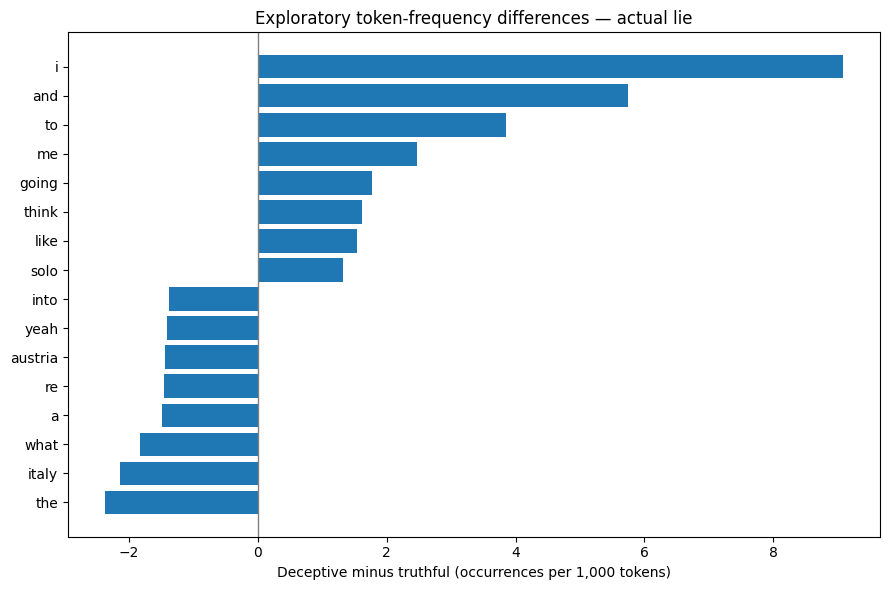

In [14]:
if not frequent.empty:
    high = frequent.nlargest(8, "difference_per_1000")
    low = frequent.nsmallest(8, "difference_per_1000")
    selected = pd.concat([low, high]).drop_duplicates("word")
    selected = selected.sort_values("difference_per_1000")

    plt.figure(figsize=(9, 6))
    plt.barh(selected["word"], selected["difference_per_1000"])
    plt.axvline(0, color="gray", linewidth=1)
    plt.xlabel("Deceptive minus truthful (occurrences per 1,000 tokens)")
    plt.title("Exploratory token-frequency differences — actual lie")
    plt.tight_layout()
    plt.show()
else:
    print("No tokens met the minimum-frequency criterion.")

#### Check vocabulary leakage and out-of-vocabulary words


In [15]:
for task in ["actual_lie", "suspected_lie"]:
    vectorizer = vectorizers[task]
    before = len(vectorizer.vocabulary_)
    for split in ["validation", "test"]:
        X = bow[task][split]
        assert X.shape[1] == before

    # A synthetic word that is not present in the learned vocabulary
    unseen_word = "uniqueinventedtoken987654321"
    assert unseen_word not in vectorizer.vocabulary_
    probe = vectorizer.transform([unseen_word])
    print(task, "| vocabulary:", before,
          "| unknown-token nonzero features:", probe.nnz)

print("Training-only vocabulary check passed.")

actual_lie | vocabulary: 7790 | unknown-token nonzero features: 0
suspected_lie | vocabulary: 7545 | unknown-token nonzero features: 0
Training-only vocabulary check passed.


#### Compare vocabulary statistics across tasks


In [16]:
task_summary = []
for task in ["actual_lie", "suspected_lie"]:
    X = bow[task]["train"]
    frame = datasets[task]["train"]
    task_summary.append({
        "task": task,
        "training_messages": len(frame),
        "truthful_or_not_suspected": int((frame["target"] == 0).sum()),
        "lie_or_suspected": int((frame["target"] == 1).sum()),
        "vocabulary_size": X.shape[1],
        "nonzero_features": X.nnz,
        "mean_nonzero_terms_per_message": round(X.nnz / len(frame), 2) if len(frame) else 0
    })

display(pd.DataFrame(task_summary))

,task,training_messages,truthful_or_not_suspected,lie_or_suspected,vocabulary_size,nonzero_features,mean_nonzero_terms_per_message
0,actual_lie,13132,12541,591,7790,241530,18.39
1,suspected_lie,12025,11459,566,7545,222359,18.49


#### Analyze suspected-lie vocabulary differences


In [17]:
suspected_table = normalized_word_table("suspected_lie")
suspected_frequent = suspected_table[
    suspected_table["target_0_count"] + suspected_table["target_1_count"] >= 20
]

print("Relatively more frequent when the receiver suspected a lie:")
display(
    suspected_frequent.sort_values(
        "difference_per_1000", ascending=False
    ).head(12)
)

print("Relatively more frequent when the receiver did not suspect a lie:")
display(
    suspected_frequent.sort_values(
        "difference_per_1000"
    ).head(12)
)

Relatively more frequent when the receiver suspected a lie:


,word,target_0_count,target_1_count,per_1000_target_0,per_1000_target_1,difference_per_1000
3301,i,11294,783,45.633061,54.583479,8.950418
375,and,4773,335,19.285160,23.353085,4.067925
4258,my,1417,118,5.725345,8.225863,2.500518
7396,wintergreen,7,34,0.028283,2.370164,2.341881
7524,you,8094,501,32.703559,34.925061,2.221502
7270,was,827,69,3.341468,4.810038,1.468570
6537,t,2432,161,9.826421,11.223423,1.397001
7116,us,452,46,1.826292,3.206692,1.380400
3378,in,3307,211,13.361832,14.708958,1.347126
6552,take,698,58,2.820248,4.043221,1.222973


Relatively more frequent when the receiver did not suspect a lie:


,word,target_0_count,target_1_count,per_1000_target_0,per_1000_target_1,difference_per_1000
2701,france,1279,41,5.167760,2.858139,-2.309622
5636,s,2645,122,10.687041,8.504705,-2.182336
7337,what,1409,53,5.693021,3.694667,-1.998354
683,be,2063,95,8.335488,6.622517,-1.712972
3111,he,1325,53,5.353622,3.694667,-1.658955
468,are,1120,42,4.525326,2.927849,-1.597476
6079,so,1548,69,6.254647,4.810038,-1.444608
108,about,1025,43,4.141481,2.997560,-1.143921
2229,england,1084,48,4.379869,3.346114,-1.033755
6688,think,1234,57,4.985939,3.973510,-1.012429


#### Explore common-word coverage in an example


In [18]:
sample = "I will support you. I will not support you."
analyzer = vectorizers["actual_lie"].build_analyzer()

print("Original:", sample)
print("Tokens used by CountVectorizer:", analyzer(sample))
print("Nonzero BoW terms in the fitted vocabulary:")

sample_X = vectorizers["actual_lie"].transform([sample])
sample_terms = pd.DataFrame({
    "word": vectorizers["actual_lie"].get_feature_names_out()[sample_X.indices],
    "count": sample_X.data
})
display(sample_terms.sort_values("word"))

Original: I will support you. I will not support you.
Tokens used by CountVectorizer: ['i', 'will', 'support', 'you', 'i', 'will', 'not', 'support', 'you']
Nonzero BoW terms in the fitted vocabulary:


,word,count
0,i,2
1,not,1
2,support,2
3,will,2
4,you,2
